In [1]:
import numpy as np
import scipy.stats as stats

# 1. Ingresamos los resultados exactos del Point Estimate Method (PEM)
# Estos son los 4 Critical SRF que se ven en tu primera imagen correspondientes a las 4 corridas
srf_values = np.array([1.29, 1.06, 1.21, 0.98])

# 2. Calculamos la Media de los SRF
# Promedio simple de los 4 valores
mean_srf = np.mean(srf_values)

# 3. Calculamos la Desviación Estándar de los SRF
# NOTA CLAVE: RS2 usa la desviación estándar muestral (grados de libertad = n - 1). 
# En numpy, esto se logra seteando ddof=1 (Delta Degrees of Freedom).
std_srf = np.std(srf_values, ddof=1)

# 4. Calculamos la Probabilidad de Falla (PF)
# Asumiendo una distribución normal, calculamos el área bajo la curva por debajo de 1.0.
# loc = media, scale = desviación estándar
pf_decimal = stats.norm.cdf(1.0, loc=mean_srf, scale=std_srf)
pf_percentage = pf_decimal * 100

# --- Imprimimos los resultados ---
print("--- Resultados del Análisis Probabilístico (PEM) ---")
print(f"Valores SRF ingresados: {srf_values}")
print(f"Media del Critical SRF calculada:      {mean_srf:.4f}  (RS2 reporta: 1.14)")
print(f"Desv. Est. del Critical SRF calculada: {std_srf:.4f}  (RS2 reporta: 0.1406)")
print(f"Probabilidad de Falla (PF) calculada:  {pf_percentage:.2f} % (RS2 reporta: 16.85 %)")

--- Resultados del Análisis Probabilístico (PEM) ---
Valores SRF ingresados: [1.29 1.06 1.21 0.98]
Media del Critical SRF calculada:      1.1350  (RS2 reporta: 1.14)
Desv. Est. del Critical SRF calculada: 0.1406  (RS2 reporta: 0.1406)
Probabilidad de Falla (PF) calculada:  16.85 % (RS2 reporta: 16.85 %)


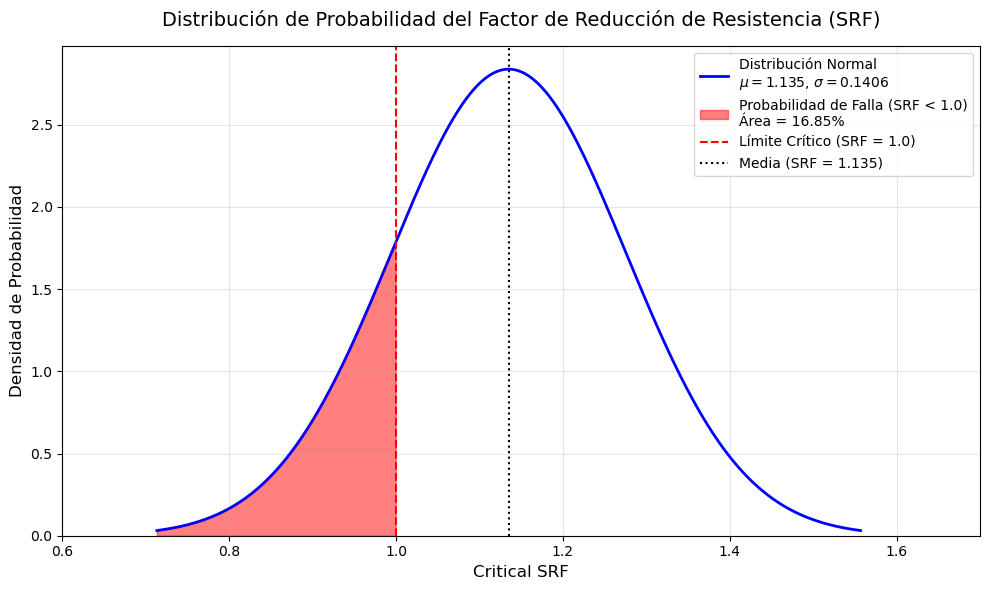

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# Parámetros obtenidos de tu análisis en RS2
media = mean_srf
desviacion_estandar = std_srf
pf = pf_percentage
limite_falla = 1.0

# 1. Configurar el eje X (creamos un rango de valores para dibujar la curva suave)
# Vamos desde 3 desviaciones estándar a la izquierda hasta 3 a la derecha
x = np.linspace(media - 3*desviacion_estandar, media + 3*desviacion_estandar, 1000)

# 2. Calcular los valores del eje Y (la forma de la campana de Gauss)
y = stats.norm.pdf(x, media, desviacion_estandar)

# 3. Iniciar el gráfico
plt.figure(figsize=(10, 6))
plt.plot(x, y, label=f'Distribución Normal\n$\mu={media:.3f}$, $\sigma={desviacion_estandar:.4f}$', color='blue', linewidth=2)

# 4. Sombrear el área de Probabilidad de Falla (SRF < 1.0)
x_falla = x[x < limite_falla]
y_falla = y[x < limite_falla]
plt.fill_between(x_falla, y_falla, color='red', alpha=0.5, label=f'Probabilidad de Falla (SRF < 1.0)\nÁrea = {pf:.2f}%')

# 5. Líneas de referencia
plt.axvline(limite_falla, color='red', linestyle='--', linewidth=1.5, label='Límite Crítico (SRF = 1.0)')
plt.axvline(media, color='black', linestyle=':', linewidth=1.5, label=f'Media (SRF = {media:.3f})')

# 6. Etiquetas y formato
plt.title('Distribución de Probabilidad del Factor de Reducción de Resistencia (SRF)', fontsize=14, pad=15)
plt.xlabel('Critical SRF', fontsize=12)
plt.ylabel('Densidad de Probabilidad', fontsize=12)
plt.legend(loc='upper right', fontsize=10)
plt.grid(alpha=0.3)
plt.xlim(0.6, 1.7) # Ajustar límites visuales
plt.ylim(bottom=0)

# Mostrar el gráfico
plt.tight_layout()
plt.show()